## Model 3: Decision Tree Regressor (CART)

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### 1. Load Dataset

In [45]:
df = pd.read_csv("dataset/gas_turbine_processed.csv")
df.head()

,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,NOX
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,81.952
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,82.377
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,83.776
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,82.505
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,82.028


### 2. Train Test Split (Trees do not require feature scaling)

In [46]:
X = df.drop('NOX', axis=1)
y = df['NOX']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

### 3. Base Model Training (Default Decision Tree)

In [47]:
base_dt = DecisionTreeRegressor(random_state=42)
base_dt.fit(X_train, y_train)

y_train_base = base_dt.predict(X_train)
y_test_base = base_dt.predict(X_test)

print("Base tree depth:", base_dt.get_depth())
print("Base leaf count:", base_dt.get_n_leaves())

Base tree depth: 38
Base leaf count: 29332


### 4. Base Model Evaluation Metrics (has Overfitting)

In [48]:
base_metrics = pd.DataFrame({
    'Train Set': [
        mean_absolute_error(y_train, y_train_base),
        mean_squared_error(y_train, y_train_base),
        np.sqrt(mean_squared_error(y_train, y_train_base)),
        r2_score(y_train, y_train_base)
    ],
    'Test Set': [
        mean_absolute_error(y_test, y_test_base),
        mean_squared_error(y_test, y_test_base),
        np.sqrt(mean_squared_error(y_test, y_test_base)),
        r2_score(y_test, y_test_base)
    ]
}, index=['MAE', 'MSE', 'RMSE', 'R2']).round(4)

print("Base Decision Tree Metrics (High variance / Overfitting on Train):")
display(base_metrics)

Base Decision Tree Metrics (High variance / Overfitting on Train):


,Train Set,Test Set
MAE,0.0,3.6344
MSE,0.0,34.9280
RMSE,0.0,5.9100
R2,1.0,0.7364


### 5. Hyperparameter Tuning (Pruning via max_depth and min_samples_leaf)

In [49]:
param_grid = {
    'max_depth': [10, 14, 18],
    'min_samples_split': [5, 10],
    'min_samples_leaf': [2, 4]
}

grid_dt = GridSearchCV(DecisionTreeRegressor(random_state=42), param_grid, cv=5, scoring='r2', n_jobs=-1)
grid_dt.fit(X_train, y_train)

# In GridSearchCV, best attributes are accessed via best_params_, best_score_, best_estimator_:
print("Best Parameters (.best_params_): ", grid_dt.best_params_)
print(f"Best CV Score (.best_score_):     {grid_dt.best_score_:.4f}")
print("Best Model (.best_estimator_):    ", grid_dt.best_estimator_)

tuned_dt = grid_dt.best_estimator_

Best Parameters (.best_params_):  {'max_depth': 14, 'min_samples_leaf': 4, 'min_samples_split': 10}
Best CV Score (.best_score_):     0.7678
Best Model (.best_estimator_):     DecisionTreeRegressor(max_depth=14, min_samples_leaf=4, min_samples_split=10,
                      random_state=42)


### 6. Tuned Model Evaluation Metrics (Train & Test)

In [50]:
y_train_tuned = tuned_dt.predict(X_train)
y_test_tuned = tuned_dt.predict(X_test)

tuned_metrics = pd.DataFrame({
    'Train Set': [
        mean_absolute_error(y_train, y_train_tuned),
        mean_squared_error(y_train, y_train_tuned),
        np.sqrt(mean_squared_error(y_train, y_train_tuned)),
        r2_score(y_train, y_train_tuned)
    ],
    'Test Set': [
        mean_absolute_error(y_test, y_test_tuned),
        mean_squared_error(y_test, y_test_tuned),
        np.sqrt(mean_squared_error(y_test, y_test_tuned)),
        r2_score(y_test, y_test_tuned)
    ]
}, index=['MAE', 'MSE', 'RMSE', 'R2']).round(4)

print("Tuned Decision Tree Metrics (Generalization improved):")
display(tuned_metrics)

Tuned Decision Tree Metrics (Generalization improved):


,Train Set,Test Set
MAE,2.3018,3.4723
MSE,11.9185,29.0701
RMSE,3.4523,5.3917
R2,0.9132,0.7806


### 7. Comparison: Base vs Tuned & R2 Increase

In [51]:
dt_comparison = pd.DataFrame({
    'Base Decision Tree': base_metrics['Test Set'],
    'Tuned Decision Tree': tuned_metrics['Test Set']
})
display(dt_comparison)

base_r2 = base_metrics.loc['R2', 'Test Set']
tuned_r2 = tuned_metrics.loc['R2', 'Test Set']
diff_r2 = tuned_r2 - base_r2

print(f"Base Test R2:          {base_r2:.4f}")
print(f"Tuned Test R2:         {tuned_r2:.4f}")
print(f"Increase in R2 Score:  {diff_r2:+.4f} (Pruning increased test accuracy by +{diff_r2*100:.2f}%)")

,Base Decision Tree,Tuned Decision Tree
MAE,3.6344,3.4723
MSE,34.9280,29.0701
RMSE,5.9100,5.3917
R2,0.7364,0.7806


Base Test R2:          0.7364
Tuned Test R2:         0.7806
Increase in R2 Score:  +0.0442 (Pruning increased test accuracy by +4.42%)


### 8. Plots: Feature Importances & Predicted vs Actual

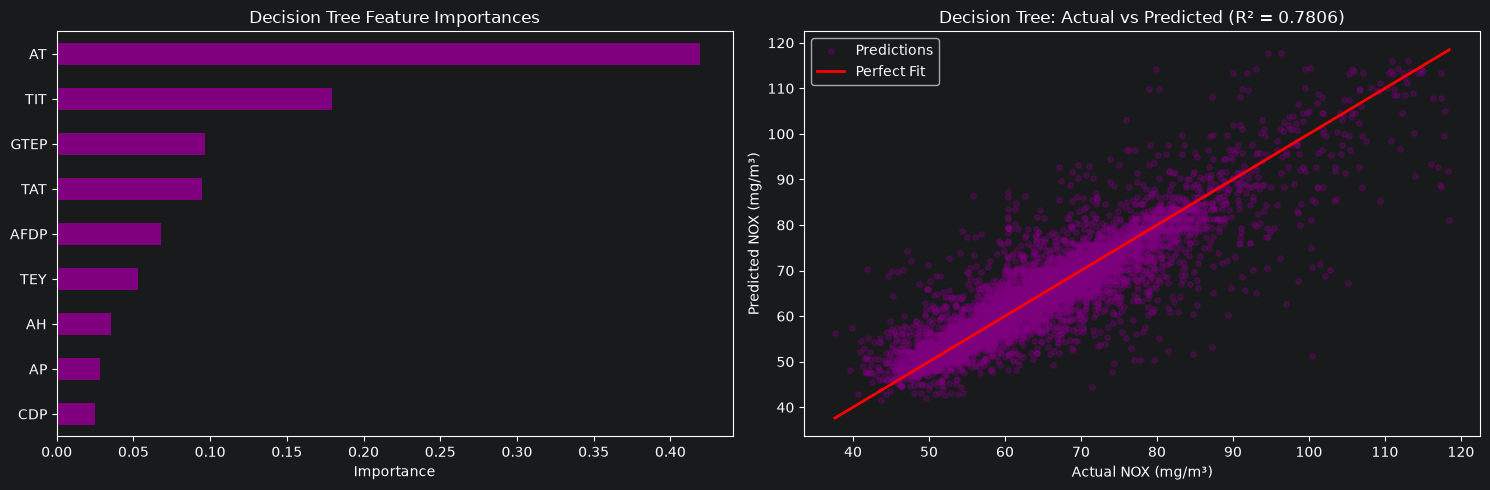

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Feature importances
feat_imp = pd.Series(tuned_dt.feature_importances_, index=X.columns).sort_values(ascending=True)
feat_imp.plot(kind='barh', ax=axes[0], color='purple')
axes[0].set_title("Decision Tree Feature Importances")
axes[0].set_xlabel("Importance")

# Predicted vs Actual
axes[1].scatter(y_test, y_test_tuned, color='purple', alpha=0.3, s=15, label='Predictions')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', lw=2, label='Perfect Fit')
axes[1].set_title(f"Decision Tree: Actual vs Predicted (R² = {tuned_r2:.4f})")
axes[1].set_xlabel("Actual NOX (mg/m³)")
axes[1].set_ylabel("Predicted NOX (mg/m³)")
axes[1].legend()

plt.tight_layout()
plt.show()

### 9. Visualizing Decision Trees: Before vs After Tuning (Structural Comparison)

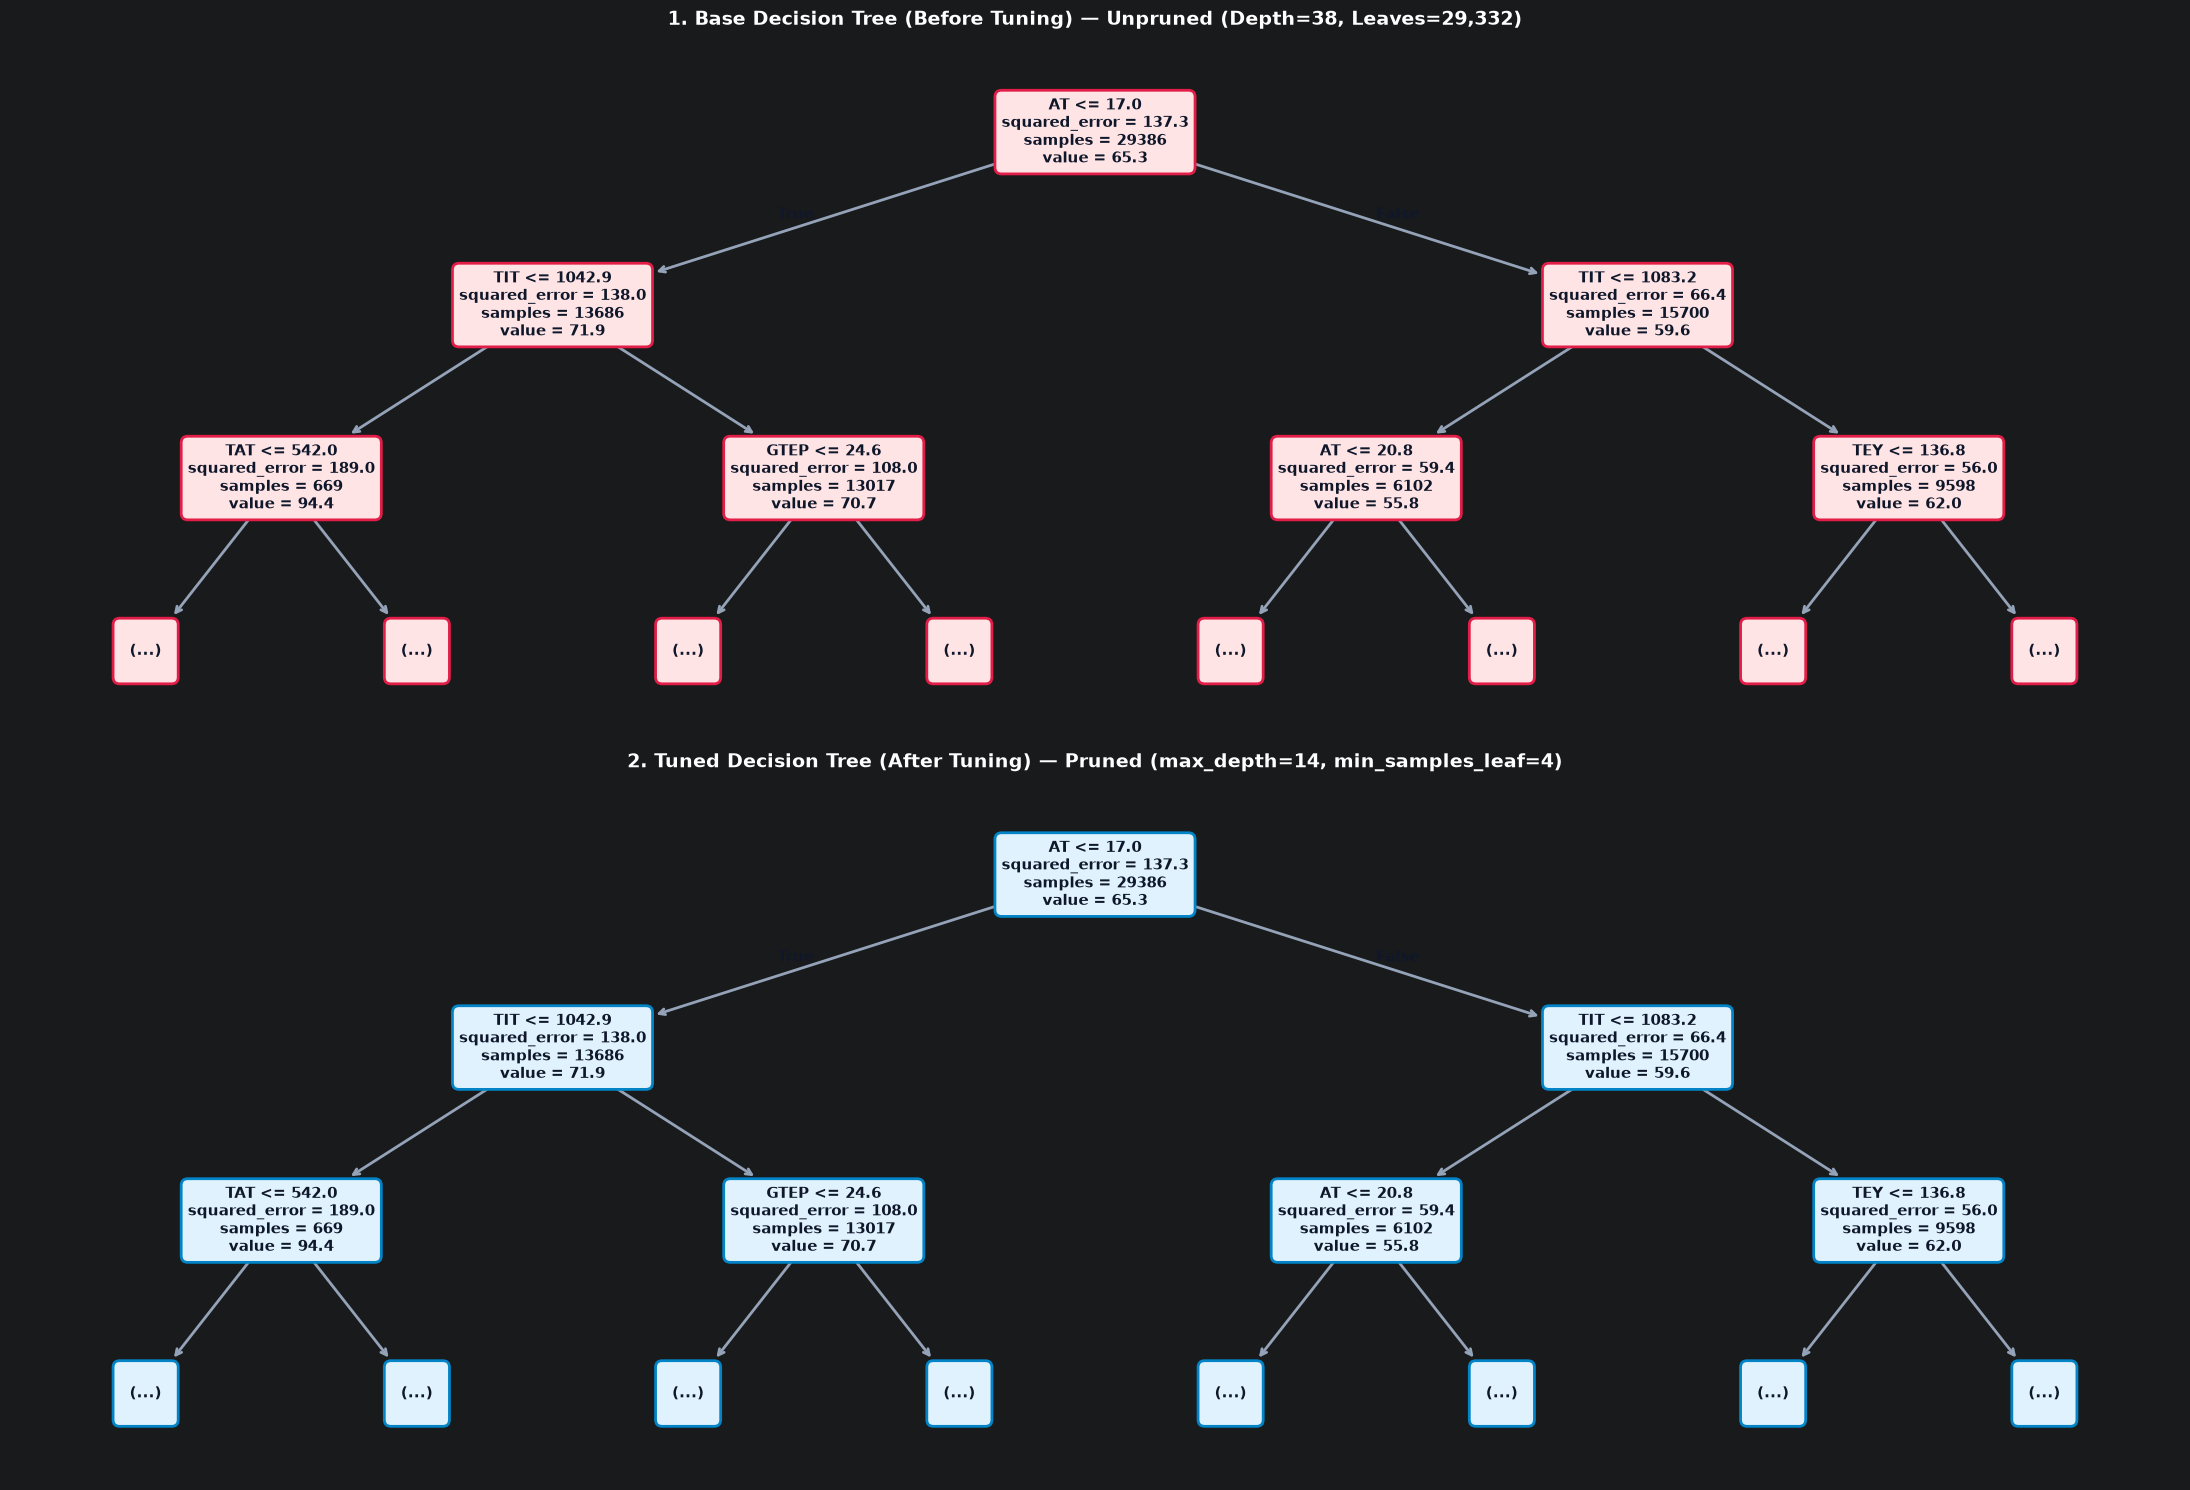

In [53]:
# High-contrast, theme-agnostic decision tree visualization (Dark Mode & Light Mode compatible)
fig, axes = plt.subplots(2, 1, figsize=(22, 15))

# 1. Base Decision Tree (Before Tuning - Overfitted)
artists_base = plot_tree(
    base_dt,
    max_depth=2,
    feature_names=list(X.columns),
    ax=axes[0],
    rounded=True,
    precision=1
)
for a in artists_base:
    # Explicitly set dark, bold text so it is 100% readable on light box backgrounds
    a.set_color('#0f172a')
    a.set_fontsize(10.5)
    a.set_fontweight('bold')
    bbox = a.get_bbox_patch()
    if bbox:
        bbox.set_facecolor('#ffe4e6')  # Soft rose fill
        bbox.set_edgecolor('#e11d48')  # Solid rose border
        bbox.set_linewidth(2)
        bbox.set_boxstyle('round,pad=0.45')
    if a.arrow_patch:
        a.arrow_patch.set_edgecolor('#94a3b8')  # Clean visible branch lines
        a.arrow_patch.set_linewidth(2)

axes[0].set_title(
    f"1. Base Decision Tree (Before Tuning) — Unpruned (Depth={base_dt.get_depth()}, Leaves={base_dt.get_n_leaves():,})",
    fontsize=14, fontweight='bold', pad=15
)

# 2. Tuned Decision Tree (After Tuning - Pruned)
artists_tuned = plot_tree(
    tuned_dt,
    max_depth=2,
    feature_names=list(X.columns),
    ax=axes[1],
    rounded=True,
    precision=1
)
for a in artists_tuned:
    # Explicitly set dark, bold text so it is 100% readable on light box backgrounds
    a.set_color('#0f172a')
    a.set_fontsize(10.5)
    a.set_fontweight('bold')
    bbox = a.get_bbox_patch()
    if bbox:
        bbox.set_facecolor('#e0f2fe')  # Soft sky-blue fill
        bbox.set_edgecolor('#0284c7')  # Solid ocean-blue border
        bbox.set_linewidth(2)
        bbox.set_boxstyle('round,pad=0.45')
    if a.arrow_patch:
        a.arrow_patch.set_edgecolor('#94a3b8')  # Clean visible branch lines
        a.arrow_patch.set_linewidth(2)

axes[1].set_title(
    f"2. Tuned Decision Tree (After Tuning) — Pruned (max_depth={tuned_dt.max_depth}, min_samples_leaf={tuned_dt.min_samples_leaf})",
    fontsize=14, fontweight='bold', pad=15
)

plt.tight_layout()
plt.show()